In [26]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

from matplotlib.ticker import MaxNLocator

import Minimal_Model_1D as M



In [12]:
def dist(omega, mu, sign_array):

    ### returns an array which gives distance from point 3,2.3 fro given omega , mu array 

    A = np.sqrt((omega - 3)**2 + (mu - 2.3)**2)

    return  A*sign_array

In [13]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0_cu = np.linspace(1, 5, NUM)
MUL0_cu = OMEGAL0_cu / 2 + 0.8
S0_cu = np.where(OMEGAL0_cu<=3, 1, -1)
RL0_cu = dist(OMEGAL0_cu, MUL0_cu, S0_cu)
change_pointl0_cu = np.abs(OMEGAL0_cu -3).argmin()

##L0 perp
OMEGAL0perp_cu = np.linspace(16.6/7, 16.6/5, NUM)
MUL0perp_cu = -2*OMEGAL0perp_cu  + 5*3/2 + 0.8
S0perp_cu = np.where(OMEGAL0perp_cu<=3, 1, -1)
RL0perp_cu = dist(OMEGAL0perp_cu, MUL0perp_cu, S0perp_cu)
change_pointl0perp_cu = np.abs(OMEGAL0perp_cu -3).argmin()

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2

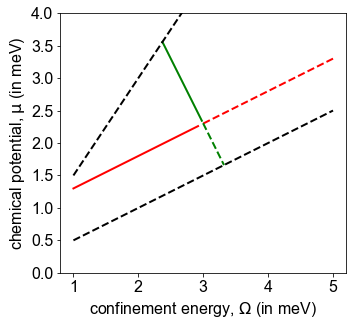

In [14]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))


# Plot lines with different labels
plt.plot(OMEGAL0_cu[:change_pointl0_cu],  MUL0_cu[:change_pointl0_cu], lw=2, label='L1',  color='red')
plt.plot(OMEGAL0_cu[change_pointl0_cu:],  MUL0_cu[change_pointl0_cu:], lw=2, label='L1', linestyle='dashed', color='red')
plt.plot(OMEGAL0perp_cu[:change_pointl0perp_cu],  MUL0perp_cu[:change_pointl0perp_cu], lw=2, label='L1', color='green')
plt.plot(OMEGAL0perp_cu[change_pointl0perp_cu:],  MUL0perp_cu[change_pointl0perp_cu:], lw=2, label='L1', linestyle='dashed', color='green')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')

# Set axis limits
plt.ylim(ymax=4, ymin=0)
#plt.xlim(xmin=1)

# Add labels
plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')

# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
#plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Set the aspect ratio to 1 using plt.gca() to get the current axes
#plt.gca().set_aspect('equal')
plt.gca().set_aspect(1)

plt.xticks(np.array([1,2,3,4,5]))

#plt.text(3, 0.5,r'subband 0', fontsize=14)
#plt.text(3.5, 4,r'subband 1', fontsize=14)
#plt.text(1.2, 4.2, r'subband 2', fontsize=14)

# Show plot
plt.tight_layout()
plt.show()


In [15]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)


##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2


NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 


Ecu_L0 = np.load("cubic_E_L0_omega_from_1.0_to_5.0_num_51.npy")
Ecu_L0perp = np.load("cubic_E_L0_perp_omega_from_2.37_to_3.32_num_51.npy")

##finding spin splitting by delta at origin pt (3, 2.3 in this case) for plotting purposes
index_org= np.argmin(np.abs(RL0_cu))
Es_org = (Ecu_L0[index_org,K//2+1]-Ecu_L0[index_org,K//2])/DELTA



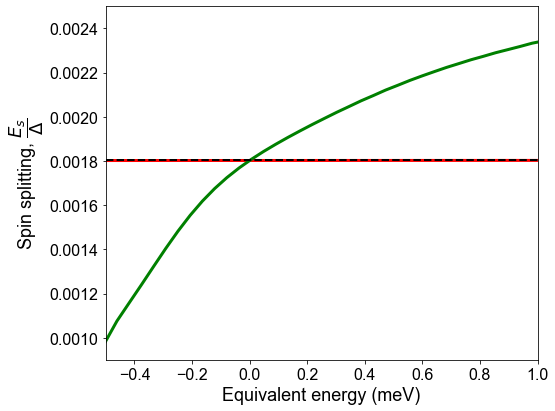

In [16]:
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(8, 6))  # Define figure size

ax.plot(RL0_cu, (Ecu_L0[:,K//2+1]-Ecu_L0[:,K//2])/DELTA, color='red', lw=3)
ax.plot(RL0perp_cu, (Ecu_L0perp[:,K//2+1]-Ecu_L0perp[:,K//2])/DELTA, color='green', lw=3)
ax.axhline(y=Es_org, color='black', linestyle='--', lw=2)

ax.set_xlabel(r'Equivalent energy (meV)', fontsize=18)  # X-axis label
ax.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=18)  # Y-axis label
#ax.grid(True)  # Add grid for better readability
#ax.legend()  # Add legend

plt.xlim(xmax=1, xmin=-0.5)
plt.ylim(ymax= 0.0025, ymin=0.0009)
plt.tight_layout()
plt.show()

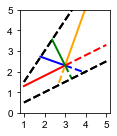

In [17]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0_li = np.linspace(2.7, 4.5, NUM)
MUL0_li = OMEGAL0_li* 2.8 -3 * 2.8 + 2.3
change_pointl0_li = np.abs(OMEGAL0_li -3).argmin()

##L0 perp
OMEGAL0perp_li = np.linspace(1.8, 4, NUM)
MUL0perp_li = OMEGAL0perp_li *(-1/2.8) + (3 / 2.8) + 2.3
change_pointl0perp_li = np.abs(OMEGAL0perp_li -3).argmin()

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size= 10)

# Create figure with a specific size
f = plt.figure(figsize=(2, 2))


# Plot lines with different labels
plt.plot(OMEGAL0_li[:change_pointl0_li],  MUL0_li[:change_pointl0_li], lw=2, label='L1', linestyle='dashed', color='orange')
plt.plot(OMEGAL0_li[change_pointl0_li:],  MUL0_li[change_pointl0_li:], lw=2, label='L1', color='orange')
plt.plot(OMEGAL0perp_li[:change_pointl0perp_li],  MUL0perp_li[:change_pointl0perp_li], lw=2, label='L1', color='blue')
plt.plot(OMEGAL0perp_li[change_pointl0perp_li:],  MUL0perp_li[change_pointl0perp_li:], lw=2, label='L1', linestyle='dashed', color='blue')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')



# Plot lines with different labels
plt.plot(OMEGAL0_cu[:change_pointl0_cu],  MUL0_cu[:change_pointl0_cu], lw=2, label='L1',  color='red')
plt.plot(OMEGAL0_cu[change_pointl0_cu:],  MUL0_cu[change_pointl0_cu:], lw=2, label='L1', linestyle='dashed', color='red')
plt.plot(OMEGAL0perp_cu[:change_pointl0perp_cu],  MUL0perp_cu[:change_pointl0perp_cu], lw=2, label='L1', color='green')
plt.plot(OMEGAL0perp_cu[change_pointl0perp_cu:],  MUL0perp_cu[change_pointl0perp_cu:], lw=2, label='L1', linestyle='dashed', color='green')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')


# Set axis limits
plt.ylim(ymax=5, ymin=0)
#plt.xlim(xmin=1)

# Add labels
#plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
#plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')

# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
#plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Set the aspect ratio to 1 using plt.gca() to get the current axes
#plt.gca().set_aspect('equal')
plt.gca().set_aspect(1)

plt.xticks(np.array([1,2,3,4,5]))

#plt.text(3, 0.5,r'subband 0', fontsize=14)
#plt.text(3.5, 4,r'subband 1', fontsize=14)
#plt.text(1.2, 4.2, r'subband 2', fontsize=14)

# Show plot
plt.tight_layout()
plt.show()


In [18]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0_li = np.linspace(2.7, 4.5, NUM)
MUL0_li = OMEGAL0_li* 2.8 -3 * 2.8 + 2.3
change_pointl0 = np.abs(OMEGAL0_li -3).argmin()
S0_li = np.where(OMEGAL0_li>=3, 1, -1)
RL0_li = dist(OMEGAL0_li, MUL0_li,S0_li)

##L0 perp
OMEGAL0perp_li = np.linspace(1.8, 4, NUM)
MUL0perp_li = OMEGAL0perp_li *(-1/2.8) + (3 / 2.8) + 2.3
change_pointl0perp = np.abs(OMEGAL0perp_li -3).argmin()
S0perp_li = np.where(OMEGAL0perp_li>=3, -1, 1)
RL0perp_li = dist(OMEGAL0perp_li, MUL0perp_li,S0perp_li)

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2


NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 


Eli_L0 = np.load("linear_E_L0_omega_from_2.7_to_4.5_num_51.npy")
Eli_L0perp = np.load("linear_E_L0_perp_omega_from_1.8_to_4.0_num_51.npy")

##finding spin splitting by delta at origin pt (3, 2.3 in this case) for plotting purposes
index_org_li= np.argmin(np.abs(RL0_li))
Es_org_li = (Eli_L0[index_org_li,K//2+1]-Eli_L0[index_org_li,K//2])/DELTA


##finding spin splitting by delta at origin pt (3, 2.3 in this case) for plotting purposes cubic
index_org_cu= np.argmin(np.abs(RL0_li))
Es_org_cu = (Ecu_L0[index_org_cu,K//2+1]-Ecu_L0[index_org_cu,K//2])/DELTA



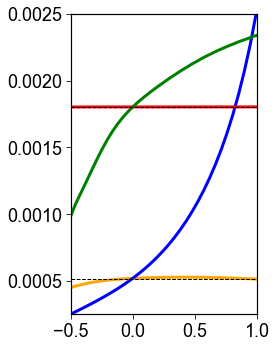

In [31]:
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=12)

#fig, ax = plt.subplots(figsize=(3.375, 3.375))  # Define figure size

fig, ax = plt.subplots(figsize=(4, 5))  # Define figure size


ax.plot(RL0_li, (Eli_L0[:,K//2+1]-Eli_L0[:,K//2])/DELTA, color='orange', lw=3)
ax.plot(RL0perp_li, (Eli_L0perp[:,K//2+1]-Eli_L0perp[:,K//2])/DELTA, color='blue', lw=3)
ax.axhline(y=Es_org_li, color='black', linestyle='--', lw=1)

#ax2 = ax.twiny()

#ax2.plot(RL0_cu, (Ecu_L0[:,K//2+1]-Ecu_L0[:,K//2])/DELTA, color='red', lw=3)
#ax2.plot(RL0perp_cu, (Ecu_L0perp[:,K//2+1]-Ecu_L0perp[:,K//2])/DELTA, color='green', lw=3)
#ax2.axhline(y=Es_org_cu, color='black', linestyle='--', lw=1)

ax.plot(RL0_cu, (Ecu_L0[:,K//2+1]-Ecu_L0[:,K//2])/DELTA, color='red', lw=3)
ax.plot(RL0perp_cu, (Ecu_L0perp[:,K//2+1]-Ecu_L0perp[:,K//2])/DELTA, color='green', lw=3)
ax.axhline(y=Es_org_cu, color='black', linestyle='--', lw=1)


#ax.set_xlabel(r'Equivalent energy (meV)')  # X-axis label
#ax.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$')  # Y-axis label
#ax.grid(True)  # Add grid for better readability
#ax.legend()  # Add legend

plt.xlim(xmax=1, xmin=-0.5)
#plt.ylim(ymax= 0.0027, ymin=0.000)
plt.ylim(ymax= 0.0025, ymin=0.00025)

#ax2.set_xlim(xmax=1, xmin=-0.5)
ax.set_xlim(xmax=1, xmin=-0.5)


plt.tick_params(axis='both', which='major', labelsize=18)  # Adjust major ticks
plt.tick_params(axis='both', which='minor', labelsize=16)  # Adjust minor ticks (if any)

# Increase tick mark length
plt.tick_params(axis='both', which='major', length=5)  # Major ticks
plt.tick_params(axis='both', which='minor', length=5)   # Minor ticks

#ax.xaxis.set_major_locator(MaxNLocator(5))  # Set 5 ticks on the x-axis
ax.yaxis.set_major_locator(MaxNLocator(5))  # Set 5 ticks on the y-axis



#plt.xlim(xmax=1, xmin=-0.5)
#plt.ylim(ymax= 0.0025, ymin=0.0009)
# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, linestyle='dotted', color='black')

plt.tight_layout()

plt.savefig('line_cuts_together.png', dpi=300) 

plt.show()



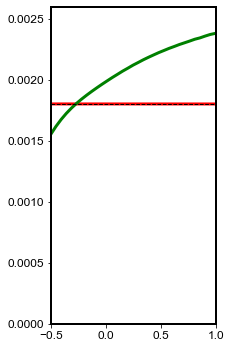

In [20]:
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=12)

#fig, ax = plt.subplots(figsize=(3.375, 3.375))  # Define figure size

fig, ax = plt.subplots(figsize=(3.375, 5))  # Define figure size


#ax.plot(RL0_li, (Eli_L0[:,K//2+1]-Eli_L0[:,K//2])/DELTA, color='orange', lw=3)
#ax.plot(RL0perp_li, (Eli_L0perp[:,K//2+1]-Eli_L0perp[:,K//2])/DELTA, color='blue', lw=3)
#ax.axhline(y=Es_org_li, color='black', linestyle='--', lw=1)

#ax2 = ax.twiny()

ax.plot(RL0_li, (Ecu_L0[:,K//2+1]-Ecu_L0[:,K//2])/DELTA, color='red', lw=3)
ax.plot(RL0perp_li, (Ecu_L0perp[:,K//2+1]-Ecu_L0perp[:,K//2])/DELTA, color='green', lw=3)
ax.axhline(y=Es_org_cu, color='black', linestyle='--', lw=1)

#ax.set_xlabel(r'Equivalent energy (meV)')  # X-axis label
#ax.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$')  # Y-axis label
#ax.grid(True)  # Add grid for better readability
#ax.legend()  # Add legend

plt.xlim(xmax=1, xmin=-0.5)
#plt.ylim(ymax= 0.0027, ymin=0.000)
plt.ylim(ymax= 0.0026, ymin=0.000)

#plt.xlim(xmax=1, xmin=-0.5)
#plt.ylim(ymax= 0.0025, ymin=0.0009)
# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

plt.tight_layout()
plt.show()